# Gradient-Free Optimization with `NevergradOptimizer`

`NevergradOptimizer` searches a bounded parameter space with the derivative-free methods of [Nevergrad](https://facebookresearch.github.io/nevergrad/) (differential evolution, CMA-ES, particle swarms, ...). Use it when gradients are unavailable or useless: objectives built from spike counts or other discrete outputs, simulations you cannot differentiate, or landscapes with many local minima.

Each iteration of `minimize`:

1. asks Nevergrad for `n_sample` candidate parameter sets;
2. evaluates **all of them at once** with your `batched_loss_fun`, whose arguments carry a leading axis of length `n_sample`;
3. tells Nevergrad the losses.

It returns the best candidate seen (or, with `use_nevergrad_recommendation=True`, Nevergrad's own recommendation). The main arguments:

| Argument | Meaning |
|---|---|
| `batched_loss_fun` | loss of `n_sample` candidates, returning an array of shape `(n_sample,)` |
| `bounds` | list of `(low, high)` pairs (arguments passed positionally) or dict (passed by name); bounds may be arrays or `brainunit` quantities; the loss always receives plain numbers |
| `n_sample` | candidates per iteration |
| `method` | any name in `nevergrad.optimizers.registry`, e.g. `'DE'`, `'CMA'`, `'PSO'`, `'TwoPointsDE'`, `'OnePlusOne'`, `'TBPSA'` |
| `num_workers` | how many candidates Nevergrad should expect to be evaluated in parallel; set it to `n_sample` |
| `seed` | makes the sampling reproducible |

## 1. Setup

In [1]:
import warnings

import brainunit as u
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import nevergrad as ng
import numpy as np

import braintools

warnings.filterwarnings("ignore", module="nevergrad")  # Nevergrad warns about some method/budget combinations
print("nevergrad", ng.__version__)

nevergrad 1.0.12


## 2. The Batched Loss and Bounds

With list bounds the loss receives one argument per bound, each with a leading candidate axis. Array-valued bounds give array-valued arguments `(n_sample, *shape)`; dict bounds are passed as keyword arguments.

In [2]:
def quadratic(x, y):  # x, y: (n_sample,)
    return (x - 2.0) ** 2 + (y + 1.0) ** 2


opt = braintools.optim.NevergradOptimizer(
    quadratic, bounds=[(-5.0, 5.0), (-3.0, 3.0)], n_sample=16, num_workers=16, method="DE", seed=0)
best = opt.minimize(n_iter=30, verbose=False)
print(f"best ({float(best[0]):.4f}, {float(best[1]):.4f}), true (2, -1); {len(opt.errors)} evaluations")


def matrix_loss(W, b):  # W: (n_sample, 3, 2), b: (n_sample, 2)
    W_target = jnp.array([[1.0, -0.5], [0.3, 1.2], [-0.8, 0.9]])
    return jnp.sum((W - W_target) ** 2, axis=(1, 2)) + jnp.sum((b - 0.5) ** 2, axis=1)


opt = braintools.optim.NevergradOptimizer(
    matrix_loss, bounds=[(-2 * jnp.ones((3, 2)), 2 * jnp.ones((3, 2))), (-jnp.ones(2), jnp.ones(2))],
    n_sample=32, num_workers=32, method="CMA", seed=0)
W_best, b_best = opt.minimize(n_iter=60, verbose=False)
print(f"array parameters: final loss {float(np.min(opt.errors)):.2e}")

best (1.9996, -0.9997), true (2, -1); 480 evaluations


array parameters: final loss 2.23e-06


`opt.errors` holds every evaluated loss and `opt.candidates` every candidate, in evaluation order, which is all you need to plot progress.

## 3. Choosing `num_workers`

Each iteration asks for `n_sample` candidates before reporting any loss. Nevergrad's methods adapt to how many evaluations run in parallel, so tell them with `num_workers=n_sample`; the default of 1 describes a strictly sequential search. The difference is large for CMA-ES. Median best loss over 10 seeds on a 3-D quadratic:

In [3]:
def bowl(a, b, c):
    return (a - 2.0) ** 2 + (b + 1.0) ** 2 + (c - 0.5) ** 2


bounds = [(-5.0, 5.0), (-3.0, 3.0), (-2.0, 2.0)]
for method in ["CMA", "DE"]:
    for workers in [1, 12]:
        errs = []
        for s in range(10):
            o = braintools.optim.NevergradOptimizer(bowl, bounds, n_sample=12, num_workers=workers, method=method, seed=s)
            o.minimize(n_iter=20, verbose=False)
            errs.append(np.min(o.errors))
        print(f"{method:4s} num_workers={workers:2d}: median best loss {np.median(errs):.1e}")

CMA  num_workers= 1: median best loss 7.9e-03


CMA  num_workers=12: median best loss 2.7e-04


DE   num_workers= 1: median best loss 4.3e-03


DE   num_workers=12: median best loss 4.3e-03


## 4. Comparing Methods on a Multimodal Landscape

The Rastrigin function $f(x) = 10d + \sum_i (x_i^2 - 10\cos 2\pi x_i)$ has a global minimum of 0 at the origin and a regular grid of local minima, where gradient descent gets stuck. Here is the median over 5 seeds of the best value after 40 iterations of 32 candidates, in 5 dimensions:

OnePlusOne   median best   0.00


PSO          median best  16.61


DE           median best   6.02


TwoPointsDE  median best   5.71


CMA          median best   0.00


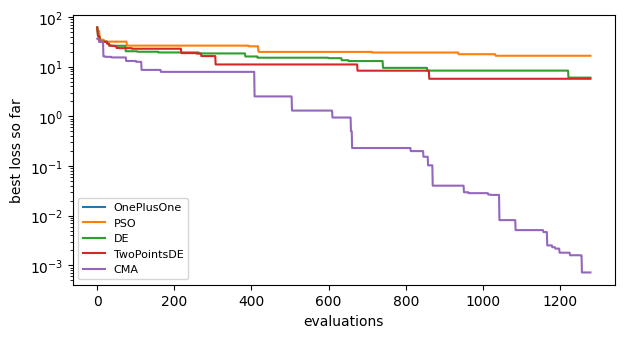

In [4]:
def rastrigin(x):  # x: (n_sample, 5)
    return 10 * x.shape[-1] + jnp.sum(x ** 2 - 10 * jnp.cos(2 * jnp.pi * x), axis=-1)


bounds = [(-5.12 * jnp.ones(5), 5.12 * jnp.ones(5))]
traces = {}
for method in ["OnePlusOne", "PSO", "DE", "TwoPointsDE", "CMA"]:
    finals, curves = [], []
    for s in range(5):
        o = braintools.optim.NevergradOptimizer(rastrigin, bounds, n_sample=32, num_workers=32, method=method, seed=s)
        o.minimize(n_iter=40, verbose=False)
        finals.append(np.min(o.errors))
        curves.append(np.minimum.accumulate(o.errors))
    traces[method] = np.median(curves, axis=0)
    print(f"{method:12s} median best {np.median(finals):6.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for method, curve in traces.items():
    ax.plot(curve, label=method)
ax.set_xlabel("evaluations")
ax.set_ylabel("best loss so far")
ax.set_yscale("log")
ax.legend(fontsize=8)
plt.show()

No single method wins everywhere, and results depend on the seed, so compare candidates over several seeds as above. Population methods (`DE`, `CMA`, `PSO`) use the batch naturally; `OnePlusOne` is a strong baseline in low dimensions.

## 5. Fitting a Neuron Model to Spike Counts

A leaky integrate-and-fire neuron, $\tau\,dV/dt = -(V - E_L) + RI$ with reset at threshold $V_{th}$, is driven by four current steps; the "data" are the spike counts in 500 ms. Spike counts are integers, so the loss is piecewise constant in $\tau$ and $V_{th}$ and its gradient is zero almost everywhere: a job for a gradient-free method.

Bounds are given as quantities. The optimizer strips the units: the loss receives **plain numbers in the unit of each lower bound** (here ms for $\tau$ and mV for $V_{th}$), and only the returned best parameters carry units again. The simulation of all `n_sample` candidates runs vectorized with `jax.lax.scan`.

In [5]:
dt = 0.1 * u.ms
currents = jnp.array([0.25, 0.3, 0.4, 0.6]) * u.nA
R, E_L, n_steps = 100 * u.Mohm, -70 * u.mV, 5000  # 500 ms


@jax.jit
def spike_counts(tau_ms, v_th_mv):
    # tau_ms, v_th_mv: (n,) -> spike counts (n, n_currents)
    drive = (R * currents).to_decimal(u.mV)  # (n_currents,)
    a = (dt.to_decimal(u.ms) / tau_ms)[:, None]
    th = v_th_mv[:, None]

    def step(v, _):
        v = v + a * (-(v - E_L.to_decimal(u.mV)) + drive)
        fired = v >= th
        return jnp.where(fired, E_L.to_decimal(u.mV), v), fired

    v0 = jnp.full((tau_ms.shape[0], drive.shape[0]), E_L.to_decimal(u.mV))
    _, fired = jax.lax.scan(step, v0, None, length=n_steps)
    return fired.sum(axis=0)


true_tau, true_vth = 15.0, -52.0
target = spike_counts(jnp.array([true_tau]), jnp.array([true_vth]))[0]
print("target spike counts:", np.asarray(target))


def count_loss(tau, v_th):  # plain numbers of shape (n_sample,): tau in ms, v_th in mV
    counts = spike_counts(tau, v_th)
    return jnp.sum((counts - target) ** 2, axis=1).astype(float)


opt = braintools.optim.NevergradOptimizer(
    count_loss,
    bounds=[(5.0 * u.ms, 40.0 * u.ms), (-60.0 * u.mV, -45.0 * u.mV)],
    n_sample=32, num_workers=32, method="CMA", seed=1)
tau_fit, vth_fit = opt.minimize(n_iter=60, verbose=False)
print(f"fitted tau = {tau_fit}, V_th = {vth_fit} (true 15 ms, -52 mV); loss {np.min(opt.errors):.0f}")
print("fitted counts:", np.asarray(spike_counts(jnp.array([tau_fit.to_decimal(u.ms)]), jnp.array([vth_fit.to_decimal(u.mV)]))[0]))

target spike counts: [26 36 55 92]


fitted tau = 15.550082 ms, V_th = -52.446354 mV (true 15 ms, -52 mV); loss 0
fitted counts: [26 36 55 92]


The fit reproduces the counts exactly, but the parameters need not equal the true ones: different $(\tau, V_{th})$ pairs can give the same integer counts. The plot of all evaluated candidates shows that the zero-loss region is a band, not a point, an identifiability limit of the data rather than of the optimizer. (`opt.candidates` stores plain numbers in the units of the bounds; only the returned best parameters carry units.)

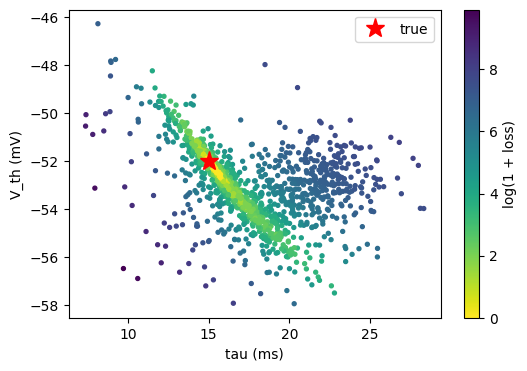

455 of 1920 evaluated candidates reproduce the counts exactly


In [6]:
cand = np.array([[float(c[0]), float(c[1])] for c in opt.candidates])  # ms, mV
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(cand[:, 0], cand[:, 1], c=np.log1p(opt.errors), s=8, cmap="viridis_r")
ax.plot(true_tau, true_vth, "r*", ms=14, label="true")
ax.set_xlabel("tau (ms)")
ax.set_ylabel("V_th (mV)")
fig.colorbar(sc, ax=ax, label="log(1 + loss)")
ax.legend()
plt.show()
print(f"{np.sum(opt.errors == 0)} of {len(opt.errors)} evaluated candidates reproduce the counts exactly")

## 6. Noisy Objectives

When the loss is noisy (for example, it involves a stochastic simulation), the lowest *observed* loss is biased: among many noisy evaluations, the minimum is mostly a lucky draw. Compare the loss reported for the returned point with its true (noise-free) loss. Noise with standard deviation 0.5 is added to the quadratic bowl:

In [7]:
noise_rng = np.random.default_rng(0)


def noisy_bowl(a, b, c):
    return bowl(a, b, c) + 0.5 * jnp.asarray(noise_rng.normal(size=a.shape))


for method in ["TBPSA", "CMA"]:
    for use_rec in [False, True]:
        reported, true_losses = [], []
        for s in range(8):
            o = braintools.optim.NevergradOptimizer(noisy_bowl, [(-5.0, 5.0), (-3.0, 3.0), (-2.0, 2.0)], n_sample=16,
                                                    num_workers=16, method=method, seed=s, use_nevergrad_recommendation=use_rec)
            p = o.minimize(n_iter=30, verbose=False)
            reported.append(np.min(o.errors))
            true_losses.append(float(bowl(*[jnp.asarray(v) for v in p])))
        label = "recommendation" if use_rec else "best observed "
        print(f"{method:5s} {label}: lowest observed loss {np.median(reported):+.3f}, true loss of returned point {np.median(true_losses):.3f}")

TBPSA best observed : lowest observed loss -1.398, true loss of returned point 0.067


TBPSA recommendation: lowest observed loss -1.367, true loss of returned point 0.068


CMA   best observed : lowest observed loss -1.390, true loss of returned point 0.065


CMA   recommendation: lowest observed loss -1.339, true loss of returned point 0.112


The lowest observed loss is far below zero, the true minimum, so it says little about the quality of the returned point. Judge a noisy fit by re-evaluating the returned parameters several times instead. `use_nevergrad_recommendation=True` returns Nevergrad's own estimate of the best point instead of the luckiest evaluation; whether that is better depends on the method and the noise level (here it makes little difference for `TBPSA` and is worse for `CMA`), so compare both on your problem.

## Summary

- `batched_loss_fun` evaluates all `n_sample` candidates at once; vectorize it (for example with `jax.lax.scan` / `jax.vmap`) so each iteration is one call.
- Bounds may be scalars, arrays, or quantities; list bounds are passed positionally, dict bounds by name. With quantity bounds the loss receives plain numbers in the lower bound's unit; the returned best parameters carry units.
- Set `num_workers=n_sample`, fix `seed` for reproducibility, and compare methods over several seeds.
- For noisy losses, the lowest observed loss is optimistic: re-evaluate the returned point, and try `use_nevergrad_recommendation=True`.
- A perfect loss does not imply identifiable parameters; inspect `opt.candidates` and `opt.errors`.